conda create -p ibmdaproject python

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

Loading 8 datasets

In [2]:
geolocation=pd.read_csv('Nexusgood_geolocation_dataset.csv')
customer=pd.read_csv('Nexusgoods_customers_dataset .csv')
order_items=pd.read_csv('Nexusgoods_order_items_dataset.csv')
order_payments=pd.read_csv('Nexusgoods_order_payments_dataset.csv')
order_reviews=pd.read_csv('Nexusgoods_order_reviews_dataset.csv')
orders_dataset=pd.read_csv('Nexusgoods_orders_dataset (1).csv')
products=pd.read_csv('Nexusgoods_products_dataset.csv')
sellers=pd.read_csv('Nexusgoods_sellers_dataset.csv')
category=pd.read_csv('product_category_name_translation.csv')

checking missing values in all table


In [3]:
geolocation.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [4]:
customer.isnull().sum()

customer_id                 0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [5]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [6]:
order_payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [7]:
order_reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       88285
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [8]:
order_reviews.drop(columns=['review_comment_title','review_comment_message'],inplace=True)

In [9]:
order_reviews.isnull().sum()

review_id                  0
order_id                   0
review_score               0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

In [10]:
orders_dataset.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [11]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [12]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [13]:
category.isnull().sum()

product_category_name            0
product_category_name_english    0
dtype: int64

checking for  duplicate rows in all the datasets

In [14]:
def print_df_name(df):
    name = [x for x in globals() if globals()[x] is df][0]
    print(f"DataFrame Name: {name}")
print ("duplicates")
list_of_dataframes=[geolocation,customer,order_items,order_payments,order_reviews,orders_dataset,products,sellers,category]
for i in list_of_dataframes:
    print_df_name(i)
    print(i.duplicated().sum())

duplicates
DataFrame Name: geolocation
261836
DataFrame Name: customer
0
DataFrame Name: order_items
0
DataFrame Name: order_payments
0
DataFrame Name: order_reviews
0
DataFrame Name: orders_dataset
0
DataFrame Name: products
0
DataFrame Name: sellers
0
DataFrame Name: category
0


In [15]:
order_payments.shape

(103886, 5)

In [16]:
((order_payments['payment_value'] > 0)==True).sum()

np.int64(103877)

In [17]:
print("Unique values in each DataFrame:")
print(customer['customer_id'].unique().shape[0])
print(order_items['order_id'].unique().shape[0])
print(products['product_id'].unique().shape[0])
print(order_reviews['order_id'].unique().shape[0])
print (orders_dataset['order_id'].unique().shape[0])

print("total values in each DataFrame:")
print(customer['customer_id'].shape[0])
print(order_items['order_id'].shape[0])
print(products['product_id'].shape[0])
print(order_reviews['order_id'].shape[0])
print (orders_dataset['order_id'].shape[0])

Unique values in each DataFrame:
99441
98666
32951
99441
99441
total values in each DataFrame:
99441
112650
32951
100000
99441


In [18]:
# One review per order: keep the most recent
order_reviews['review_answer_timestamp'] = pd.to_datetime(
    order_reviews['review_answer_timestamp'], dayfirst=True)
order_reviews = (order_reviews
                 .sort_values('review_answer_timestamp')
                 .drop_duplicates(subset='order_id', keep='last'))

print(order_reviews.shape[0])                  # expect 99441
print(order_reviews['order_id'].is_unique)     # expect True

99441
True


In [19]:
order_reviews.head(5)

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
37828,6916ca4502d6d3bfd39818759d55d536,bfbd0f9bdef84302105ad712db648a6c,1,06-10-2016 00:00,2016-10-07 18:32:00
5538,49f695dffa457eaba90d388a5c37e942,e5215415bb6f76fe3b7cb68103a0d1c0,1,09-10-2016 00:00,2016-10-11 14:31:00
60918,743d98b1a4782f0646898fc915ef002a,e2144124f98f3bf46939bc5183104041,4,15-10-2016 00:00,2016-10-16 03:20:00
28280,53752edb26544dd41c1209f582c9c589,b8b9d7046c083150cb5360b83a8ebb51,5,16-10-2016 01:00,2016-10-16 15:45:00
41350,b2d5d8db2a841d27a72e4c06c6212368,9aa3197e4887919fde0307fc23601d7a,4,15-10-2016 00:00,2016-10-17 21:02:00


In [20]:
#  Missing delivery dates vs order status
print(orders_dataset['order_status'].value_counts())

print()

print("Orders with missing delivery dates:")
missing = orders_dataset[orders_dataset['order_delivered_customer_date'].isna()]
print(missing['order_status'].value_counts())
print()
# "delivered" orders that still have no delivery date (real data issue)
print(((orders_dataset['order_status'] == 'delivered') &
 orders_dataset['order_delivered_customer_date'].isna()).sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Orders with missing delivery dates:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

8


In [21]:
#  Orders that have no items
no_items = orders_dataset[~orders_dataset['order_id'].isin(order_items['order_id'])]
print(len(no_items))                           # expect about 775
no_items['order_status'].value_counts()

775


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [22]:
#  Are the 610 missing product values the same products?
cols = ['product_category_name', 'product_name_lenght',
        'product_description_lenght', 'product_photos_qty']
print(products[cols].isna().any(axis=1).sum())   # rows with any of these missing
print(products[cols].isna().all(axis=1).sum())   # rows with all of them missing
# If both print 610, it's the same 610 products

610
610


In [23]:
# Sanity checks
print(order_items[['price', 'freight_value']].describe())
print((order_items['price'] <= 0).sum())

order_payments['payment_type'].value_counts()

fmt = '%d-%m-%Y %H:%M'                          # use the format your dates have
purchase = pd.to_datetime(orders_dataset['order_purchase_timestamp'], format=fmt)
delivered = pd.to_datetime(orders_dataset['order_delivered_customer_date'], format=fmt)
print((delivered < purchase).sum())              # delivered before purchased

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000
0
0


In [24]:
#  Category translation gaps
chk = products.merge(category, on='product_category_name', how='left')
# categories that exist but have no English name (excludes the 610 with no category)
gaps = chk[chk['product_category_name_english'].isna() &
           chk['product_category_name'].notna()]['product_category_name'].unique()
print(gaps)

<StringArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: str


creating a master table which contains\
 order details (status, purchase date, delivery dates, customer ID) from the orders table.\
 the customer's state from the customers table.\
 the product's category from the products table.\
 the English category name from the translation table, using your two manual fixes and the "unknown" label for missing categories.\
one-review-per-order table (the cleaned one).

assumptions\
Sales = item price only (freight stays separate).\
Orders that count as sales = everything except canceled and unavailable.\
Date for time analysis = purchase date.\
Late = status delivered, has a delivery date, and delivered date later than estimated date.

In [25]:
orders_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [26]:
list_of_columns=['order_purchase_timestamp','order_approved_at','order_delivered_customer_date','order_delivered_carrier_date','order_estimated_delivery_date']
for i in list_of_columns:
    orders_dataset[i] = pd.to_datetime(orders_dataset[i], format='%d-%m-%Y %H:%M')


In [27]:
orders_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [28]:
#  Date range of purchases
print(orders_dataset['order_purchase_timestamp'].min())
print(orders_dataset['order_purchase_timestamp'].max())
#  Orders per month
per_month = orders_dataset.groupby(
    orders_dataset['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].count()
print(per_month)
#  Delivered before purchased
print((orders_dataset['order_delivered_customer_date']
       < orders_dataset['order_purchase_timestamp']).sum())

2016-09-04 21:15:00
2018-10-17 17:30:00
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64
0


In [29]:
# orders_dataset amd customer join on customer_id
merger1=orders_dataset.merge(customer,on='customer_id',how='left')
merger1.shape

(99441, 11)

In [30]:
# order_items  with previous merger1 on order id
merger2=merger1.merge(order_items,on='order_id',how='inner')
merger2.shape

(112650, 17)

In [31]:
#products with previous merger2 on product id
merger3=merger2.merge(products,on='product_id',how='left')
merger3.shape

(112650, 25)

In [32]:
#category with previous merger3 on product_category_name
merger4=merger3.merge(category,on='product_category_name',how='left')
merger4.shape

(112650, 26)

In [33]:
# how many rows have no English name
print(merger4['product_category_name_english'].isna().sum())
# split them into the two groups
no_english = merger4['product_category_name_english'].isna()
print((no_english & merger4['product_category_name'].isna()).sum())    # product has no category at all
print((no_english & merger4['product_category_name'].notna()).sum())    # has a category, but no translation)

1627
1603
24


In [34]:
# no category at all -> "unknown"
merger4.loc[merger4['product_category_name'].isna(), 'product_category_name_english'] = 'unknown'
# the two categories with no translation -> manual English names
merger4.loc[merger4['product_category_name'] == 'pc_gamer',
            'product_category_name_english'] = 'pc_gamer'
merger4.loc[merger4['product_category_name'] == 'portateis_cozinha_e_preparadores_de_alimentos',
            'product_category_name_english'] = 'portable_kitchen_food_preparers'

In [35]:
# how many rows have no English name
print(merger4['product_category_name_english'].isna().sum())
# split them into the two groups
no_english = merger4['product_category_name_english'].isna()
print((no_english & merger4['product_category_name'].isna()).sum())    # product has no category at all
print((no_english & merger4['product_category_name'].notna()).sum())    # has a category, but no translation)

0
0
0


In [36]:
#order_reviews with previous merger4 on order id
merger5=merger4.merge(order_reviews,on='order_id',how='left')
merger5.shape

(112650, 30)

In [37]:
#  rename merger5  to master for clarity
master = merger5.copy()
#some columns to help with analysis
# Time columns (from purchase date)
master['purchase_year'] = master['order_purchase_timestamp'].dt.year
master['purchase_quarter'] = master['order_purchase_timestamp'].dt.quarter
master['purchase_month'] = master['order_purchase_timestamp'].dt.to_period('M')

#  Delivery status
delivered = master['order_status'] == 'delivered'
has_date = master['order_delivered_customer_date'].notna()
is_late = master['order_delivered_customer_date'] > master['order_estimated_delivery_date']

conditions = [
    delivered & ~has_date,               # delivered but no date (the 8 orders)
    delivered & has_date & is_late,
    delivered & has_date & ~is_late,
]
choices = ['delivered_no_date', 'late', 'on_time']
master['delivery_status'] = np.select(conditions, choices, default='not_delivered')

#  Sales flag
master['is_sale'] = ~master['order_status'].isin(['canceled', 'unavailable'])

In [38]:
print(master.shape)                                # rows must still be 112650
print(master['delivery_status'].value_counts())    # must add up to 112650
print(master['is_sale'].value_counts())            # how many rows the sales flag removes

(112650, 35)
delivery_status
on_time              101475
late                   8714
not_delivered          2453
delivered_no_date         8
Name: count, dtype: int64
is_sale
True     112101
False       549
Name: count, dtype: int64


In [39]:
master.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code_prefix,customer_city,...,product_category_name_english,review_id,review_score,review_creation_date,review_answer_timestamp,purchase_year,purchase_quarter,purchase_month,delivery_status,is_sale
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,2017-10-02 11:07:00,2017-10-04 19:55:00,2017-10-10 21:25:00,2017-10-18,3149,sao paulo,...,housewares,a54f0611adc9ed256b57ede6b6eb5114,4,11-10-2017 00:00,2017-10-12 03:43:00,2017,4,2017-10,on_time,True
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,2018-07-26 03:24:00,2018-07-26 14:31:00,2018-08-07 15:27:00,2018-08-13,47813,barreiras,...,perfumery,8d5266042046a06655c8db133d120ba5,4,08-08-2018 00:00,2018-08-08 18:37:00,2018,3,2018-07,on_time,True
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,2018-08-08 08:55:00,2018-08-08 13:50:00,2018-08-17 18:06:00,2018-09-04,75265,vianopolis,...,auto,e73b67b67587f7644d5bd1a52deb1b01,5,18-08-2018 00:00,2018-08-22 19:07:00,2018,3,2018-08,on_time,True
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,2017-11-18 19:45:00,2017-11-22 13:39:00,2017-12-02 00:28:00,2017-12-15,59296,sao goncalo do amarante,...,pet_shop,359d03e676b3c069f62cadba8dd3f6e8,5,03-12-2017 00:00,2017-12-05 19:21:00,2017,4,2017-11,on_time,True
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,2018-02-13 22:20:00,2018-02-14 19:46:00,2018-02-16 18:17:00,2018-02-26,9195,santo andre,...,stationery,e50934924e227544ba8246aeb3770dd4,5,17-02-2018 00:00,2018-02-18 13:02:00,2018,1,2018-02,on_time,True


In [40]:
master.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_zip_code_prefix', 'customer_city', 'customer_state',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'product_category_name',
       'product_name_lenght', 'product_description_lenght',
       'product_photos_qty', 'product_weight_g', 'product_length_cm',
       'product_height_cm', 'product_width_cm',
       'product_category_name_english', 'review_id', 'review_score',
       'review_creation_date', 'review_answer_timestamp', 'purchase_year',
       'purchase_quarter', 'purchase_month', 'delivery_status', 'is_sale'],
      dtype='str')


Task1\
Top Categories by Total Price:\
Identify and visually represent the top 10 product categories by total sales.


In [41]:
df1=master.loc[master['is_sale'], ['order_id','product_category_name_english','price']].copy()
ans=df1.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

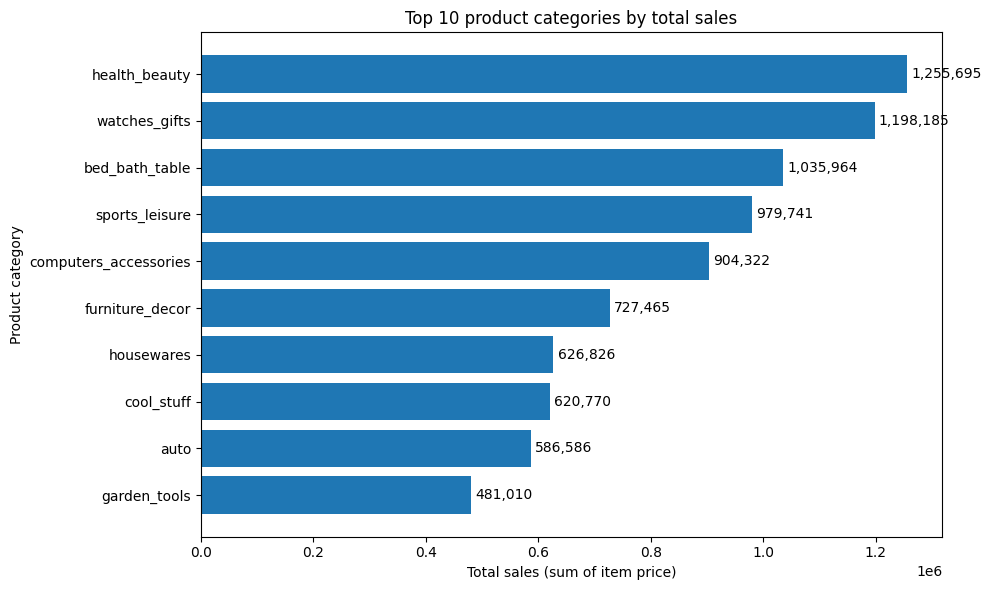

In [42]:
top10=ans.head(10)
plt.figure(figsize=(10, 6))
bars = plt.barh(top10.index[::-1], top10.values[::-1])
plt.bar_label(bars, labels=[f'{v:,.0f}' for v in top10.values[::-1]], padding=3)
plt.xlabel('Total sales (sum of item price)')
plt.ylabel('Product category')
plt.title('Top 10 product categories by total sales')
plt.tight_layout()
plt.show()

from the graph we can infer that:\
health_beauty category has highest sales \
if we combine categories like bed_bath_table,furniture_decor,houseware under a category of household its combined sales will be more than health_beauty category


2.	Delayed Orders Analysis:\
Determine the number of delayed orders in each category. An order is considered delayed if the actual delivery date is later than the estimated delivery date.


In [43]:
#  Only delivered orders that have a delivery date
df2 = master.loc[master['delivery_status'].isin(['on_time', 'late']),['order_id', 'product_category_name_english', 'delivery_status']].copy()
#  One row per order per category
df2 = df2.drop_duplicates(subset=['order_id', 'product_category_name_english'])

df2['late'] = (df2['delivery_status'] == 'late').astype(int)

#  Per-category table
ans2 = df2.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'count'),
    late_orders=('late', 'sum')
).sort_values(ascending=False, by='late_orders')


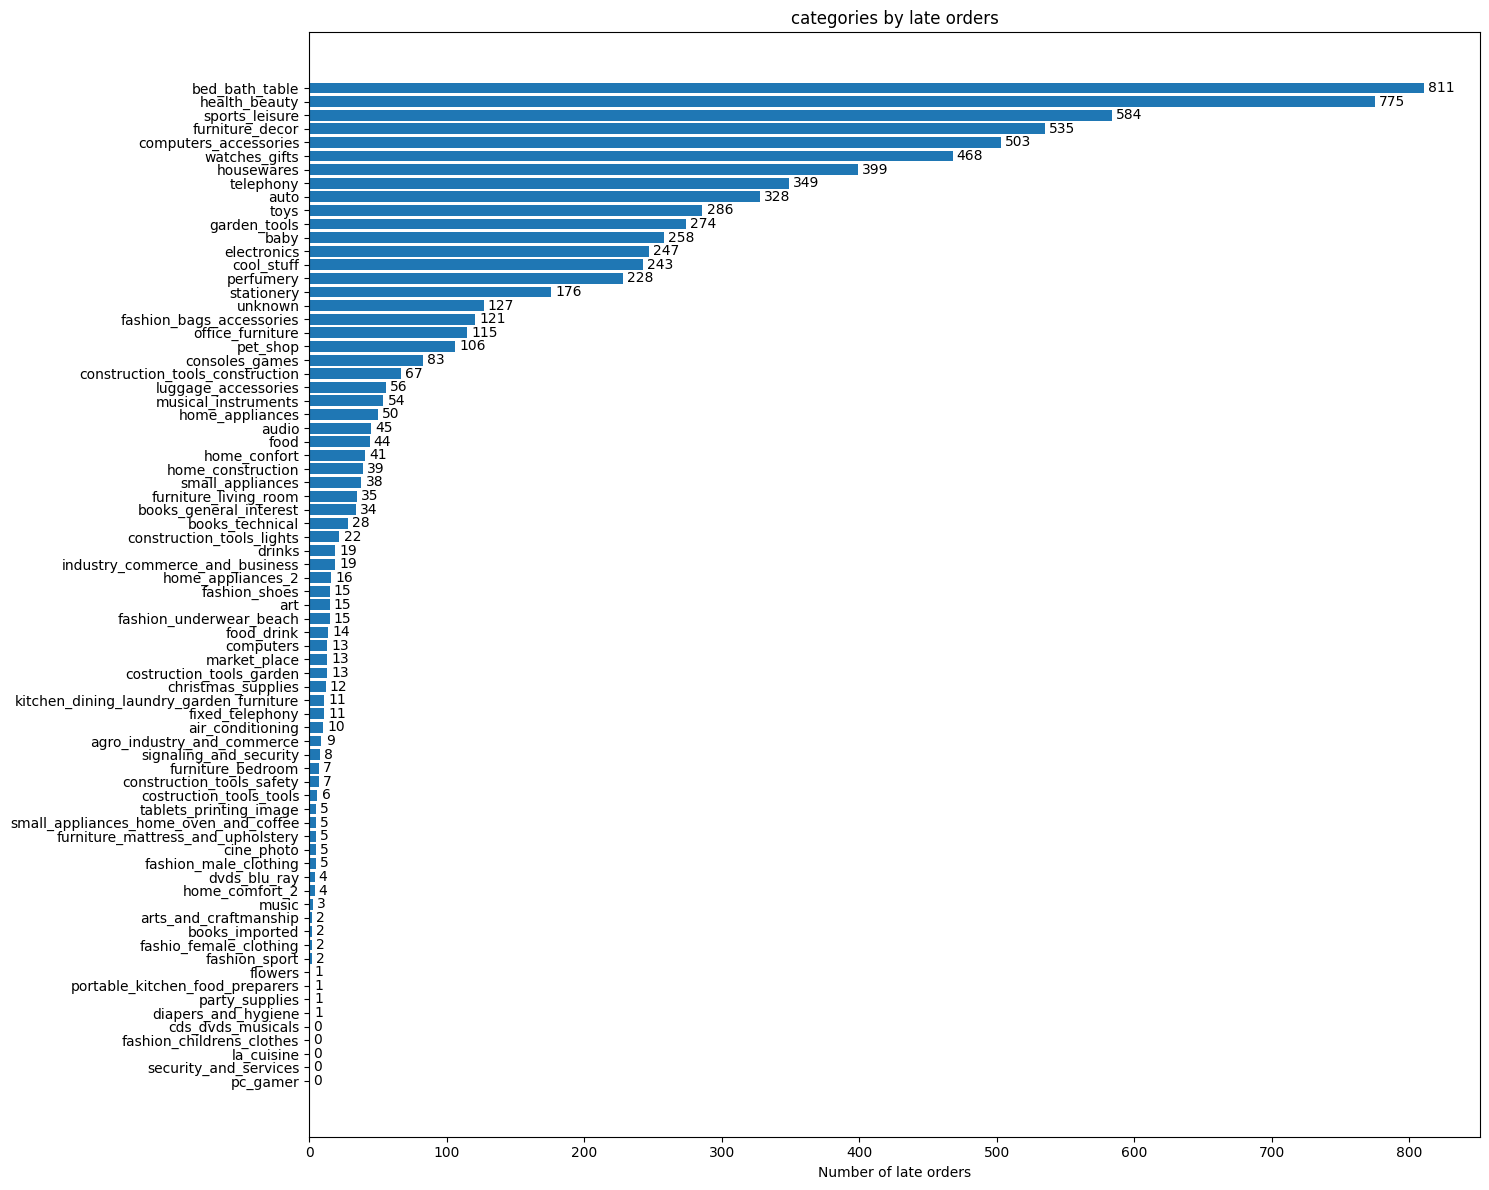

In [58]:

fig=plt.figure(figsize=(15, 12))
bars = plt.barh(ans2.index[::-1], ans2['late_orders'][::-1])
plt.bar_label(bars, padding=3)
plt.xlabel('Number of late orders')
plt.title('categories by late orders')
plt.tight_layout()
plt.show()

from above visualization we can infer that :\
bed_bath_table has most orders that were delayed 
followed by health_beauty category which has highest sales

3.	Monthly Comparison of Delayed and On-Time Orders:\
Create a  visual that compares the number of delayed orders to the number of orders received earlier for each month. 

In [45]:
df3 =master.loc[master['delivery_status'].isin(['on_time', 'late']), ['order_id','purchase_month','delivery_status','order_delivered_customer_date',
'order_estimated_delivery_date']].drop_duplicates(subset=['order_id']).copy()

df3['late_orders'] = (df3['delivery_status'] == 'late').astype(int)
df3['early_orders'] = (df3['order_delivered_customer_date'] < df3['order_estimated_delivery_date']).astype(int)
ans3=df3.groupby(['purchase_month']).agg(
    total_orders=('order_id', 'count'),
    late_orders=('late_orders', 'sum'),
    early_orders=('early_orders', 'sum'))


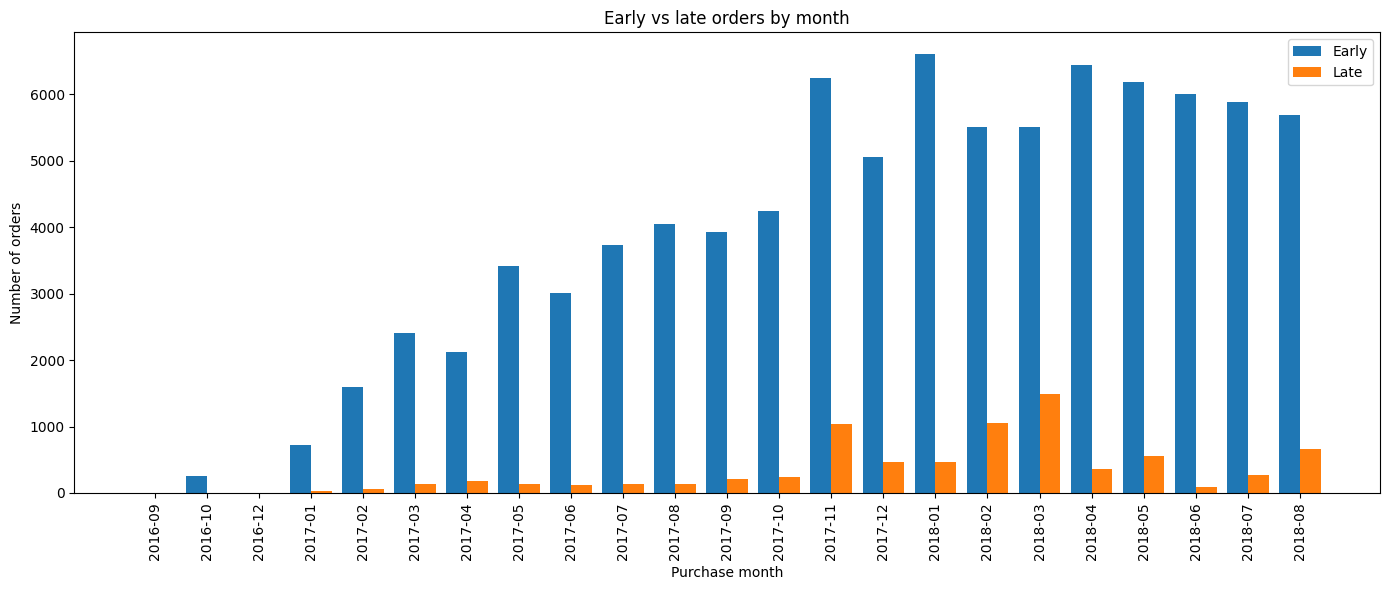

In [46]:
#  Chart: 
x = np.arange(len(ans3))
w = 0.4
plt.figure(figsize=(14, 6))
plt.bar(x - w/2, ans3['early_orders'], width=w, label='Early')
plt.bar(x + w/2, ans3['late_orders'], width=w, label='Late')
plt.xticks(x, ans3.index.astype(str), rotation=90)
plt.xlabel('Purchase month')
plt.ylabel('Number of orders')
plt.title('Early vs late orders by month')
plt.legend()
plt.tight_layout()
plt.show()

from above visualization we can infer that\
maximum deliveries that were  late were in month of march of 2018\
and maximum deliveries that were early were in month of january of 2018

4.	Payment Method Analysis:
Analyse the most frequently used payment methods by customers using a visually appealing representation, such as a pie chart or other suitable visuals.

order_payment dataset

In [47]:
df4 = order_payments[['order_id', 'payment_type', 'payment_installments', 'payment_value']].copy()
ans4=df4['payment_type'].value_counts()

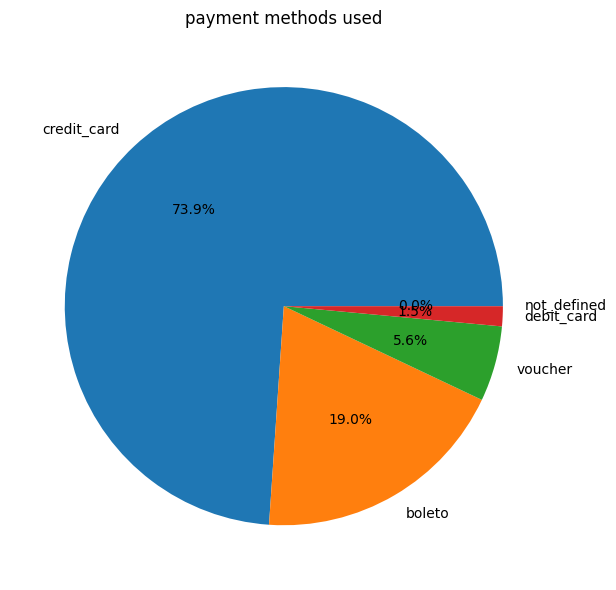

In [48]:

# 5. Two charts: share of payments (pie) and share of value (bar)
plt.figure(figsize=(14, 6))
plt.pie(ans4.values, labels=ans4.index, autopct='%1.1f%%')
plt.title('payment methods used')
plt.tight_layout()
plt.show()

from above visualization we can infer that maximum customers prefered to proceed to payment using credit cards

5.	Product Rating Analysis:\
Determine the top 10 highest-rated products and the bottom 10 lowest-rated products using a bar or column chart.



In [49]:
#  Order-product rows that have a review score (one row per order and product)
df5 = (master.loc[master['review_score'].notna(),['order_id', 'product_id', 'product_category_name_english', 'review_score']].copy())
df5=df5.drop_duplicates(subset=['order_id', 'product_id'])

#  Average score and number of reviews per product
ans5 = (df5.groupby('product_id').agg(avg_score=('review_score', 'mean'),
                n_reviews=('order_id', 'nunique'),
                category=('product_category_name_english', 'first')).reset_index())
ans5 = ans5[ans5['n_reviews'] >= 10].copy()          # ignore products with very few reviews
ans5['label'] = ans5['category'] + '_' + ans5['product_id'].str[:6]

#  Top 10 and bottom 10 (ties: more reviews ranks first)
top10 = ans5.sort_values(['avg_score', 'n_reviews'], ascending=[False, False]).head(10)
bottom10 = ans5.sort_values(['avg_score', 'n_reviews'], ascending=[True, False]).head(10)
print(top10[['label', 'avg_score', 'n_reviews']])
print(bottom10[['label', 'avg_score', 'n_reviews']])


                                 label  avg_score  n_reviews
5179              health_beauty_2722b7   5.000000         13
9949            furniture_decor_4c8b28   5.000000         11
11647  fashion_bags_accessories_59c184   5.000000         11
16718            sports_leisure_8173ca   5.000000         11
17925            sports_leisure_8b6ed4   5.000000         11
17011           furniture_decor_83aae8   5.000000         10
21496  fashion_bags_accessories_a7d756   5.000000         10
23884            sports_leisure_b9ee75   5.000000         10
31653  fashion_bags_accessories_f5d8f4   5.000000         10
8103        luggage_accessories_3e4176   4.958333         24
                              label  avg_score  n_reviews
24968                unknown_c230b4   1.181818         11
32553                   auto_fd0065   1.181818         11
26437  computers_accessories_cd46a8   1.607143         28
14110  computers_accessories_6d2fde   1.666667         12
23027                unknown_b36f3c   1

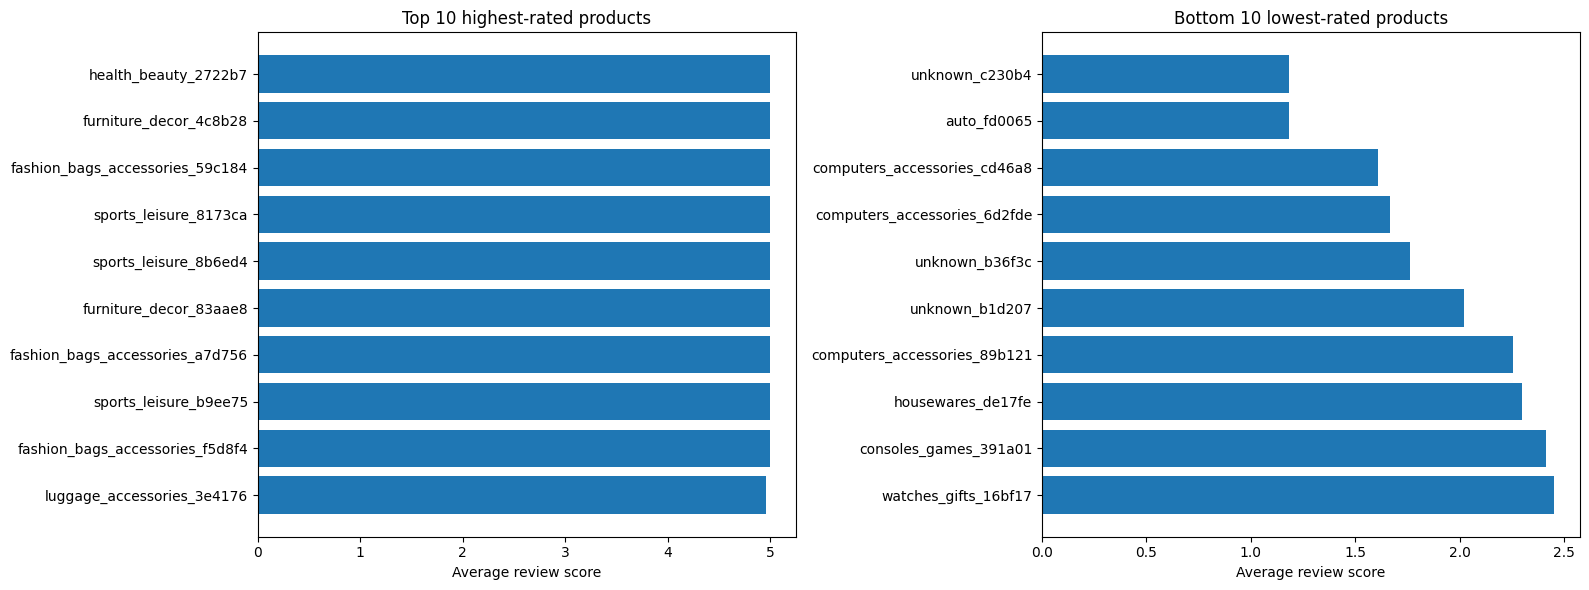

In [50]:

# 6. Two horizontal bar charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top10['label'][::-1], top10['avg_score'][::-1])
axes[0].set_title('Top 10 highest-rated products')
axes[0].set_xlabel('Average review score')
axes[1].barh(bottom10['label'][::-1], bottom10['avg_score'][::-1])
axes[1].set_title('Bottom 10 lowest-rated products')
axes[1].set_xlabel('Average review score')
plt.tight_layout()
plt.show()

from above visualization we can infer that :\
heath_beauty ,furniture_decor,
health_beauty,furniture_decor,fashion_bags_accessories,sports_leisure,sports_leisure,furniture_decor,fashion_bags_accessories,sports_leisure,fashion_bags_accessories,luggage_accessories are equally highly rated\
and auto and miscelaneous categories are poorly rated

6.	State-wise Sales Analysis:
Identify and visually represent states with high and low sales, providing a clear understanding of regional sales performance


In [ ]:
#  Sales rows only, three columns
df6 = master.loc[master['is_sale'], ['order_id', 'customer_state', 'price']].copy()
#  Per-state table
ans6 = df6.groupby('customer_state')['price'].sum().sort_values(ascending=False)


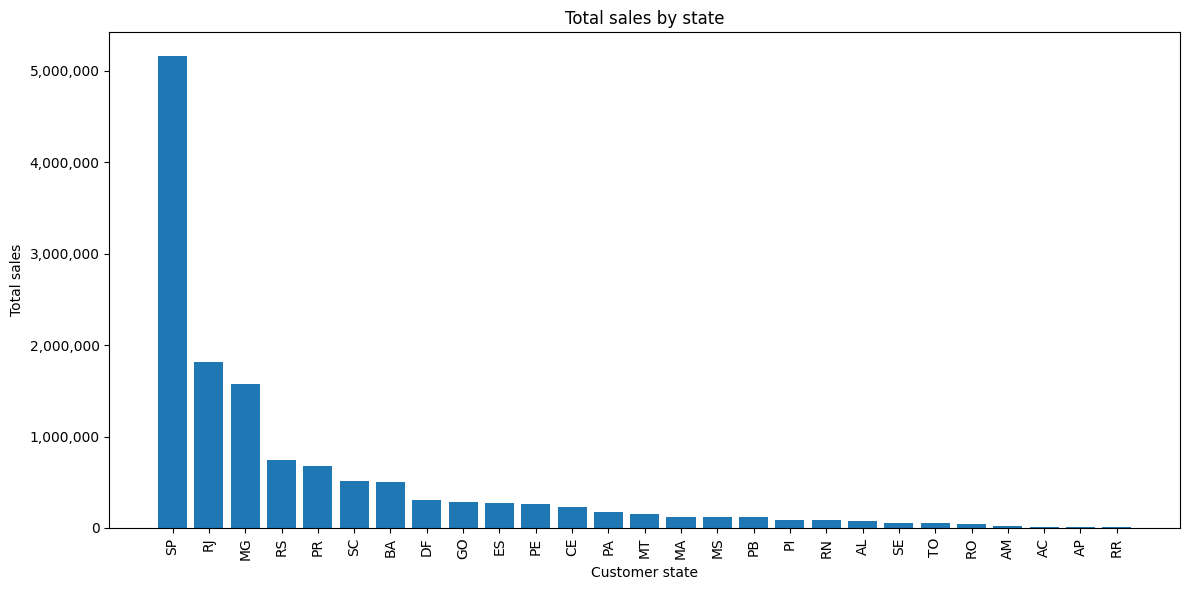

In [61]:
plt.figure(figsize=(12, 6))
plt.bar(ans6.index, ans6.values)
plt.xlabel('Customer state')
plt.ylabel('Total sales')
plt.title('Total sales by state')
plt.xticks(rotation=90)
plt.ticklabel_format(style='plain', axis='y')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: '{:,.0f}'.format(x)))
plt.tight_layout()
plt.show()

from above visualization we can infer that \
state SP contribution in sales is highest and\
state rr contribution is lowest

7.	Seasonal Sales Patterns:\
Investigate and visualize any seasonal patterns (Quarterly) or trends in sales data over the course of the year.


In [53]:
#  Sales rows only
df7 = master.loc[master['is_sale'], ['order_id', 'order_purchase_timestamp', 'price']].copy()
df7['month'] = df7['order_purchase_timestamp'].dt.to_period('M')
df7['quarter'] = df7['order_purchase_timestamp'].dt.to_period('Q')

#  Quarterly table
ans7 = df7.groupby('quarter').agg(total_sales=('price', 'sum'),
                               n_orders=('order_id', 'nunique'))




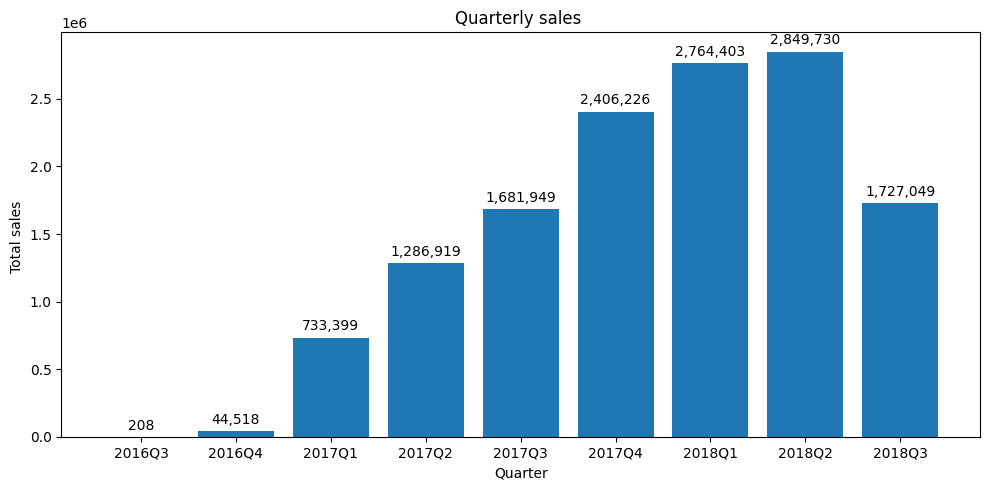

In [54]:
# 8. Chart
plt.figure(figsize=(10, 5))
bars = plt.bar(ans7.index.astype(str), ans7['total_sales'])
plt.bar_label(bars, labels=[f'{v:,.0f}' for v in ans7['total_sales']], padding=3)
plt.xlabel('Quarter')
plt.ylabel('Total sales ')
plt.title('Quarterly sales ')
plt.tight_layout()
plt.show()

from above visualization we can infer that:\
sales were increasing from year 2016 quarter 3 to year 2018 quarter 2\
there was a sudden decrease in quarter 3 of 2018

8.	 Revenue Analysis:\
Determine the total revenue generated by ShopNest Store and analyse how it changes over time (Yearly).\ Represent this information through suitable visuals to highlight trends and patterns.


In [ ]:
# Sales rows only
df8 = master.loc[master['is_sale'], ['order_id', 'order_purchase_timestamp', 'price']].copy()
df8['year'] = df8['order_purchase_timestamp'].dt.year

#  Total revenue 
total_revenue = df8['price'].sum()
print('Total revenue:', round(total_revenue, 2))

# Yearly table
ans8 = df8.groupby('year')['price'].sum()



Total revenue: 13494400.74


C:\Users\Krish\AppData\Local\Temp\ipykernel_17628\3451594810.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(['{:,.0f}'.format(x) for x in current_values])


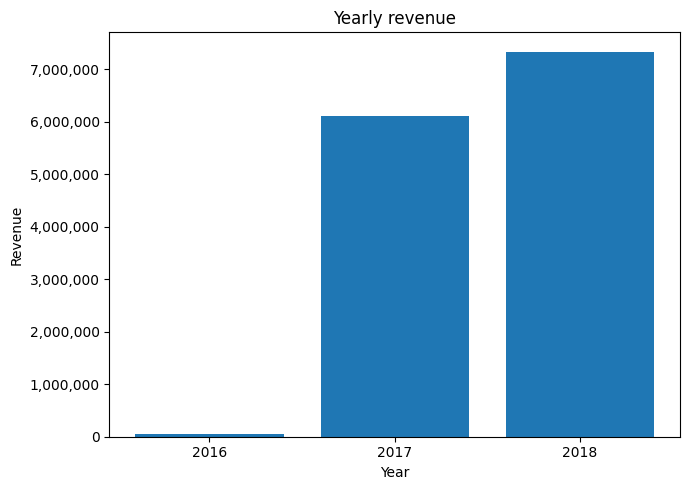

In [62]:
plt.figure(figsize=(7, 5))
plt.bar(ans8.index.astype(str), ans8.values)
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.title('Yearly revenue')
plt.gca().ticklabel_format(style='plain', axis='y')
current_values = plt.gca().get_yticks()
plt.gca().set_yticklabels(['{:,.0f}'.format(x) for x in current_values])
plt.tight_layout()

from above visualization we can infer that there was an exponential increase in revenue from year 2016 to 2017 \
and then a gradual increase from year 2017 to 2018